# RFMiD — entrenar ResNet-152 (Disease_Risk)

**Nota:** el usuario pidió "ResNet-150"; no existe en torchvision. Usamos **ResNet-152** ImageNet pretrained.

- Focal Loss (desbalance)
- Fine-tuning: `layer4` + `fc` entrenables; resto congelado
- 20 épocas por defecto; cada época imprime `train_loss` y `val_loss`

Equivalente CLI: `python scripts/train.py`

In [1]:
import sys
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import default_config
from src.data import create_dataloaders
from src.evaluate import evaluate_loader, format_metrics
from src.train import get_device, load_best_checkpoint_for_eval, train_model

config = default_config()
print(f"epochs={config.epochs}, batch_size={config.batch_size}, device={get_device()}")

epochs=20, batch_size=16, device=cpu


In [2]:
(
    train_loader,
    val_loader,
    test_loader,
    train_dataframe,
    val_dataframe,
    test_dataframe,
) = create_dataloaders(config)

for name, dataframe in [
    ("train", train_dataframe),
    ("val", val_dataframe),
    ("test", test_dataframe),
]:
    print(name, len(dataframe), dataframe["disease_risk"].value_counts().to_dict())

train 1920 {1: 1519, 0: 401}
val 640 {1: 506, 0: 134}
test 640 {1: 506, 0: 134}


In [3]:
# Entrena 20 épocas (config.epochs). Por época: train_loss | val_loss | AUC | F1 | Acc
# Si ya existe el checkpoint del baseline NO se reentrena (ponlo a True para forzarlo).
FORCE_RETRAIN = False

baseline_checkpoint_path = config.checkpoint_dir / config.best_checkpoint_name
if FORCE_RETRAIN or not baseline_checkpoint_path.is_file():
    train_model(train_loader, val_loader, config)
else:
    print(f"Checkpoint existente, se omite el entrenamiento: {baseline_checkpoint_path}")

Checkpoint existente, se omite el entrenamiento: C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk.pt


In [4]:
device = get_device()
model = load_best_checkpoint_for_eval(config, device)

val_metrics = evaluate_loader(model, val_loader, device)
test_metrics = evaluate_loader(model, test_loader, device)
print(format_metrics(val_metrics, "val"))
print(format_metrics(test_metrics, "test"))

[val] AUC=0.9313 | F1=0.9015 | Acc=0.8531 | CM=[[116, 18], [76, 430]] (n=640, pos=506)
[test] AUC=0.9610 | F1=0.9118 | Acc=0.8688 | CM=[[122, 12], [72, 434]] (n=640, pos=506)


## Grad-CAM: ¿en qué se fija el modelo?

Grad-CAM (implementado a mano en `src/explain.py`) usa los *hooks* de la última capa convolucional (`layer4[-1]`): pondera cada mapa de activación por la media de su gradiente respecto al **logit de Disease_Risk** y aplica ReLU. El resultado es un mapa de calor de las regiones que *empujan* la predicción hacia "riesgo".

Se muestran ejemplos del **test** (umbral 0.5, el de las métricas de arriba): los verdaderos positivos (TP) y negativos (TN) más confiados, y los errores más confiados (FP y FN). Las figuras se guardan en `artifacts/gradcam/`.

In [5]:
import matplotlib.pyplot as plt

from src.evaluate import collect_predictions
from src.explain import compute_gradcam_samples, plot_gradcam_grid

GRADCAM_DIR = PROJECT_ROOT / "artifacts" / "gradcam"
DECISION_THRESHOLD = 0.5

test_probabilities, test_labels, _ = collect_predictions(model, test_loader, device)
gradcam_samples = compute_gradcam_samples(
    model,
    test_dataframe,
    test_probabilities,
    test_labels,
    threshold=DECISION_THRESHOLD,
    image_size=config.image_size,
    examples_per_group=4,
)
print({group: sum(s['group'] == group for s in gradcam_samples) for group in ['TP', 'TN', 'FP', 'FN']})

{'TP': 4, 'TN': 4, 'FP': 4, 'FN': 4}


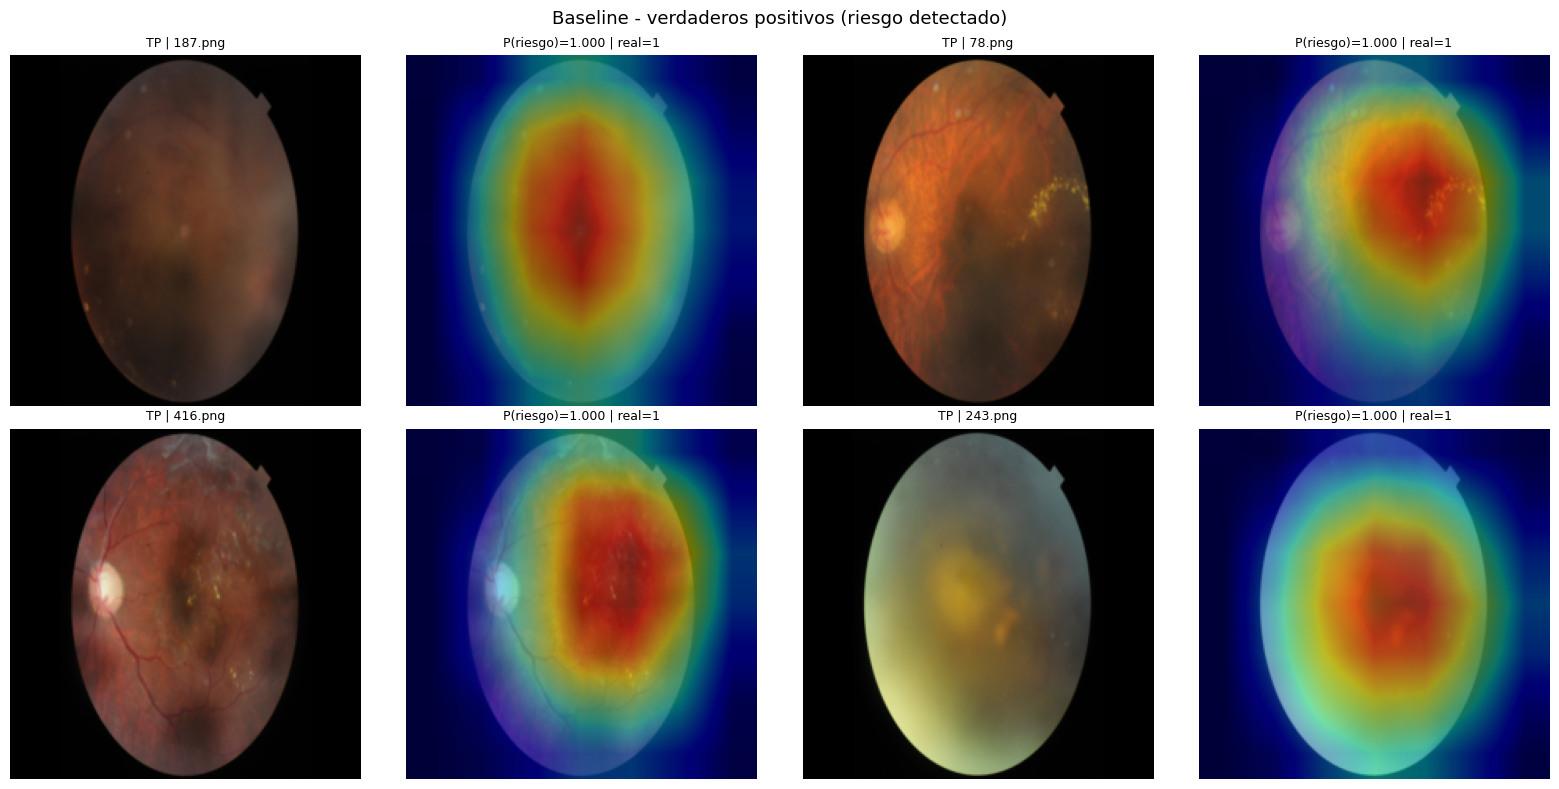

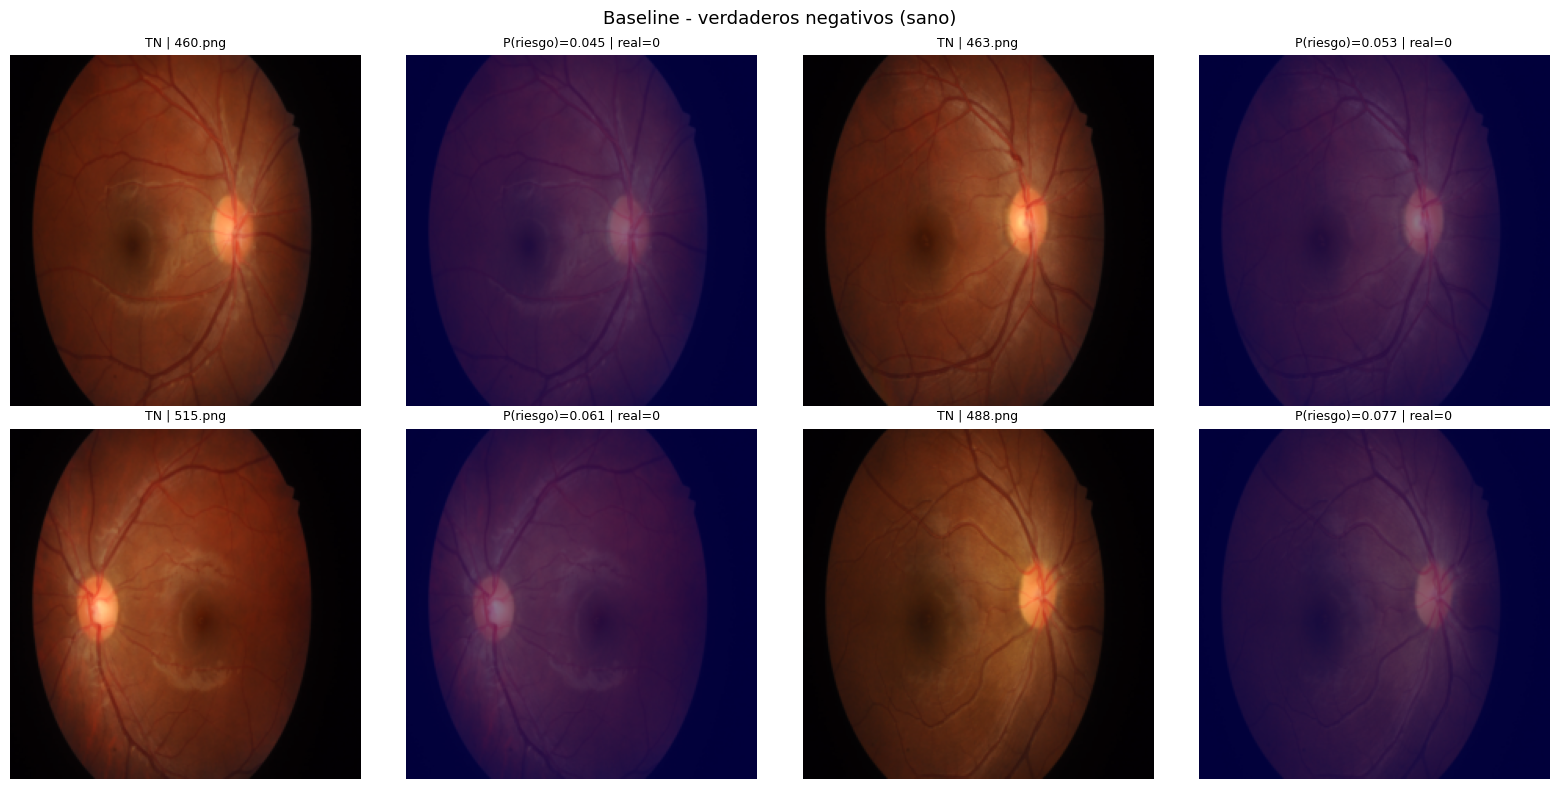

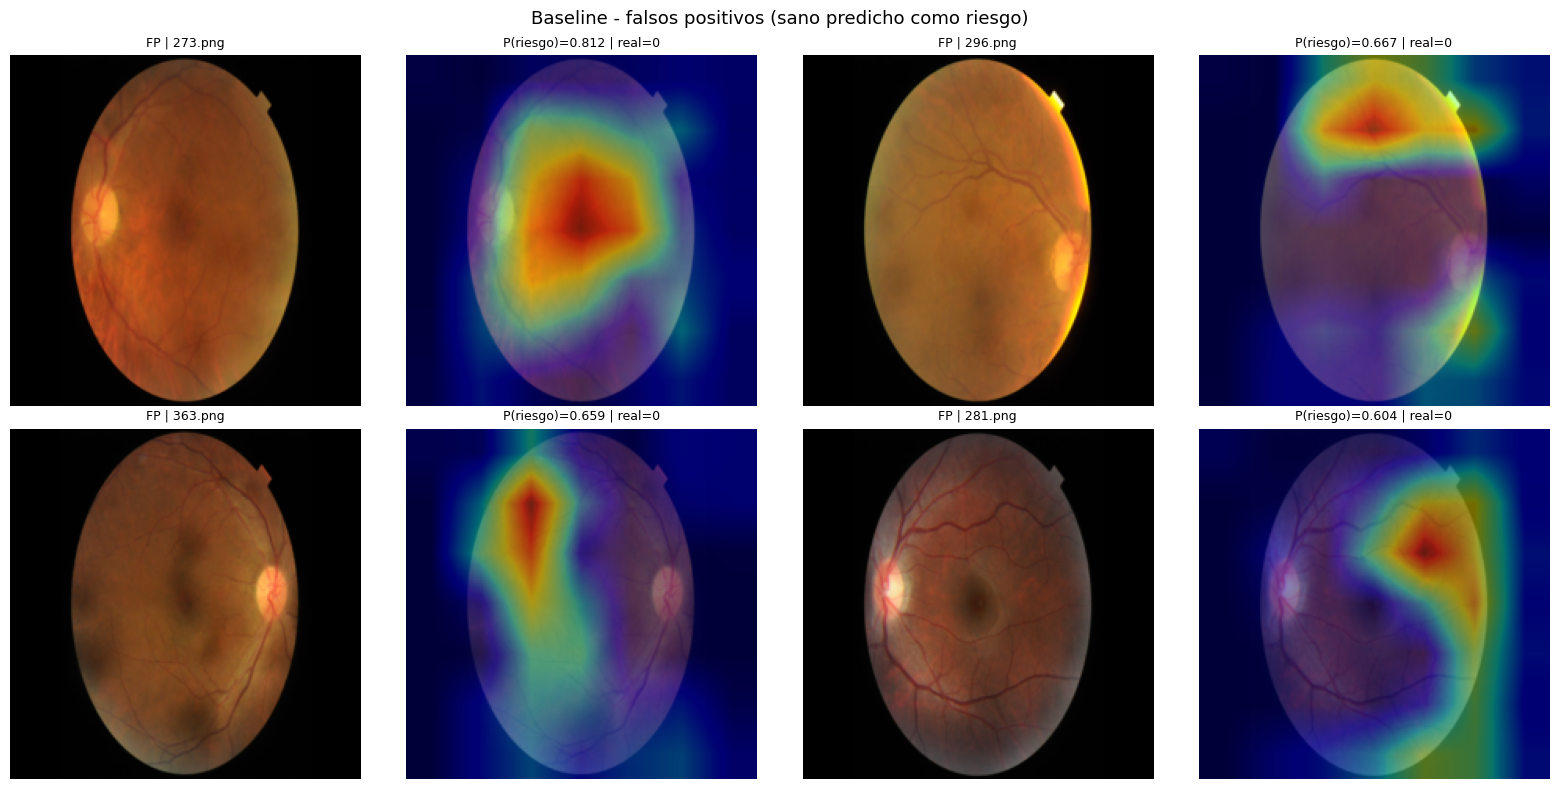

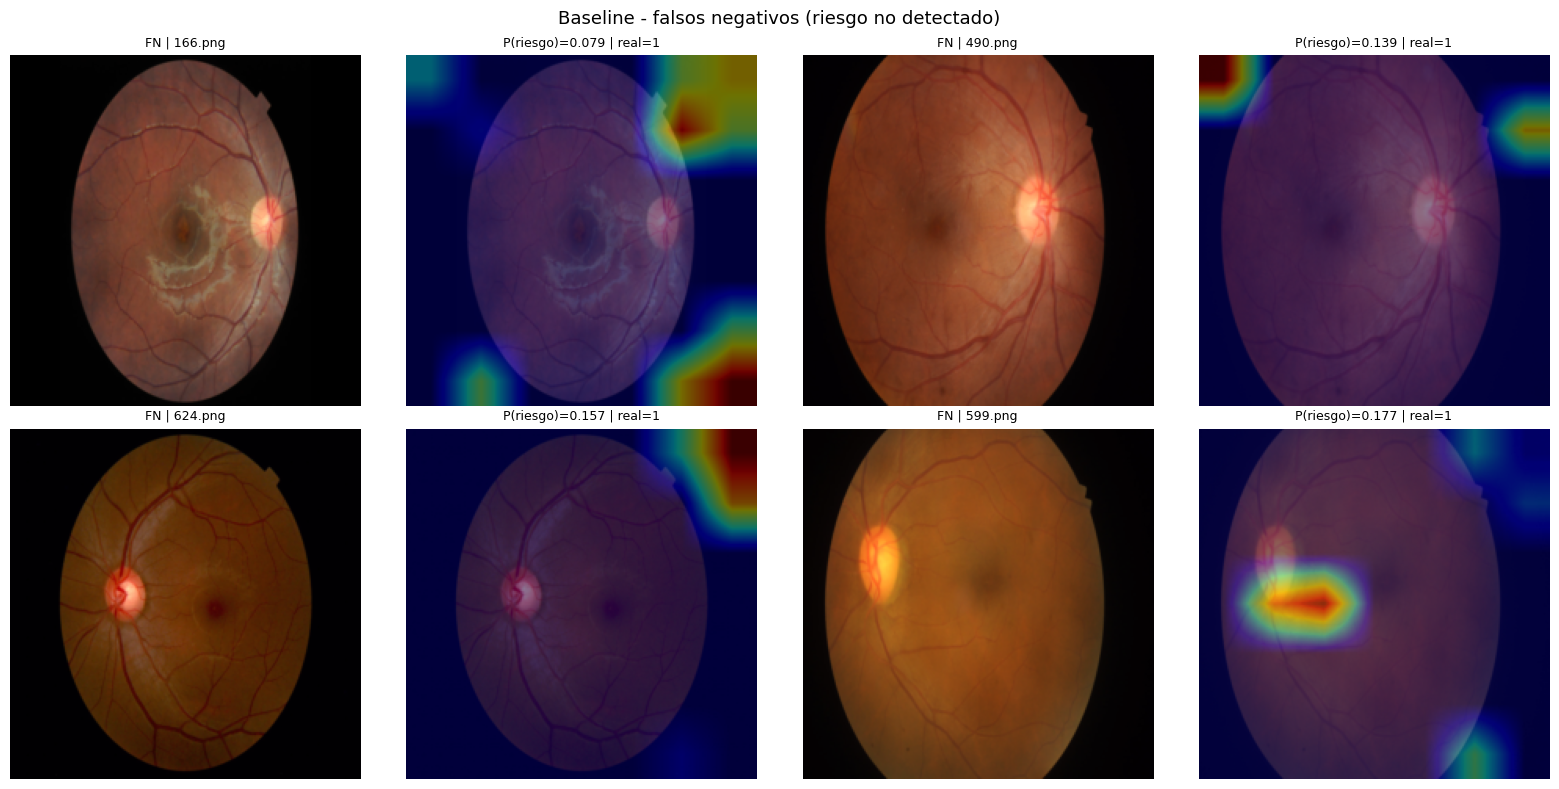

In [6]:
group_titles = {
    "TP": "Baseline - verdaderos positivos (riesgo detectado)",
    "TN": "Baseline - verdaderos negativos (sano)",
    "FP": "Baseline - falsos positivos (sano predicho como riesgo)",
    "FN": "Baseline - falsos negativos (riesgo no detectado)",
}
for group, group_title in group_titles.items():
    group_samples = [s for s in gradcam_samples if s["group"] == group]
    figure = plot_gradcam_grid(
        group_samples,
        title=group_title,
        save_path=GRADCAM_DIR / f"baseline_{group}.png",
    )
    if figure is not None:
        plt.show()

### Lectura cualitativa (baseline, test)

- **TP:** el calor se concentra en la **región central/macular y paramacular**, de forma amplia y difusa. Cuando hay lesiones visibles (exudados amarillos, hemorragias) el calor las cubre, pero en imágenes borrosas u opacas (medios turbios) se activa sobre casi todo el disco central: el modelo parece usar también *calidad/aspecto global de la imagen* y no solo lesiones localizadas.
- **TN:** activación casi nula en todo el fondo de ojo. Son retinas nítidas con disco óptico, vasos y mácula normales; no hay evidencia a favor de "riesgo" (el mapa solo explica la clase positiva).
- **FP:** el calor cae en **zonas concretas del interior** (arcos vasculares, parte superior/lateral) con probabilidades moderadas (0.60–0.81): variaciones de iluminación o textura que el modelo confunde con patología.
- **FN:** el calor se va **a las esquinas / el borde del campo** (fuera de la retina útil) o a zonas sin lesión; p. ej. la imagen 166 tiene una lesión anular visible en la mácula y el modelo no la mira. Son casos de patologías sutiles que el modelo no capta, y señalan cierta dependencia de artefactos del borde.

Conclusión: el modelo se centra en la retina central (donde está la patología más habitual) y casi nunca en el disco óptico por sí solo; los errores se asocian a artefactos de borde, iluminación y patologías sutiles. Grad-CAM es cualitativo: sirve para detectar atajos, no para demostrar que el modelo razona como un clínico.